# Boreas-RT IMU and LiDAR exploration
Raw sensor data, ground-truth reference motion and synchronization through the public package API. No smoothing, noise injection, resampling, ICP, deskew or SLAM is performed. Only a small selected set of point clouds is read.

[Official format reference](https://github.com/utiasASRL/pyboreas/blob/master/DATA_RT_REFERENCE.md). **Applanix IMU is correlated with the ground truth; raw DMU is the default calibration input.**

In [1]:
from pathlib import Path
import os
import sys

# Run from the repository root or this notebook directory; editable installs also work.
for parent in (Path.cwd(), *Path.cwd().parents):
    if (parent / "src/boreas_dataset").is_dir():
        sys.path.insert(0, str(parent / "src"))
        break

import numpy as np
import matplotlib.pyplot as plt
from boreas_dataset.lidar import LIDAR_SOURCES
from boreas_dataset import (
    BoreasDataset, relative_seconds, timestamp_statistics, nearest_timestamps,
    motion_magnitudes, accumulate_lidar_scans,
)
get_ipython().run_line_magic("matplotlib", "inline")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10})
COLORS = ["#2878B5", "#E07A28", "#36865C"]

In [2]:
DATA_ROOT = os.environ.get("BOREAS_DATA_ROOT")
SEQUENCE_ID = "boreas-2024-12-03-12-54"
IMU_SOURCE = "dmu"
LIDAR_SOURCE = "velodyne"
TIME_START = None  # absolute UTC seconds, inclusive
TIME_END = None
MAX_LIDAR_SCANS = 20
POINTS_PER_SCAN = 10_000
SHOW_PLOTS = True
COMPARE_INFILL = True
SHOW_AEVA_IMU = True
SYNC_WINDOW_S = 10.0
SYNC_TOLERANCE_S = 0.1  # mark matches beyond this bound as rejected (DMU dropouts)

def show_figure(fig):
    fig.tight_layout()
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)

sequence = BoreasDataset(DATA_ROOT).sequence(SEQUENCE_ID)
print("Sources:", sequence.sensors)
print("Map-like files:", sequence.inventory()["map_like_files"] or "None found; demonstrate local scan accumulation")

Sources: {'imu': ['dmu', 'dmu_infilled', 'aeva', 'applanix'], 'lidar': ['velodyne', 'aeva'], 'detected_unimplemented': ['radar', 'camera']}
Map-like files: None found; demonstrate local scan accumulation


## A. Native IMU measurements
`timestamps_s` (`t_utc`) preserves UTC alignment. `timestamps_ns` retains integer precision; `relative_seconds()` subtracts epochs before converting to float. Gyroscope and accelerometer arrays are also available as `data_gyr` and `data_acc`. Accelerometer axes stay in the selected physical sensor frame, with gravity left as supplied.

In [3]:
imu = sequence.imu(IMU_SOURCE, time_start=TIME_START, time_end=TIME_END)
if len(imu.timestamps_ns) < 2:
    raise ValueError("Select an interval containing at least two IMU samples")
stats = timestamp_statistics(imu.timestamps_ns)
t_imu = relative_seconds(imu.timestamps_ns)
print("Frame:", imu.frame_id, "source:", imu.metadata["source"])
print("Shapes:", imu.data_gyr.shape, imu.data_acc.shape)
print(f"UTC seconds: {imu.t_utc[0]:.9f} to {imu.t_utc[-1]:.9f}")
print("Exact nanoseconds:", imu.timestamps_ns[[0, -1]])
print("Frequency and timestamp statistics:", {k: v for k, v in stats.items() if k not in ["gap_indices", "gap_durations_s"]})
print("Gaps:", len(stats["gap_indices"]), "largest [s]:", np.max(stats["gap_durations_s"], initial=0))

Frame: dmu source: dmu
Shapes: (196429, 3) (196429, 3)
UTC seconds: 1733248461.886082649 to 1733249447.860108614
Exact nanoseconds: [1733248461886082560 1733249447860108544]
Frequency and timestamp statistics: {'count': 196429, 'start_s': 1733248461.8860826, 'end_s': 1733249447.8601086, 'duration_s': 985.974025984, 'median_dt_s': 0.004995072000000001, 'frequency_hz': 200.1973144731447, 'min_dt_s': 0.004994816, 'max_dt_s': 0.304695296}
Gaps: 26 largest [s]: 0.304695296


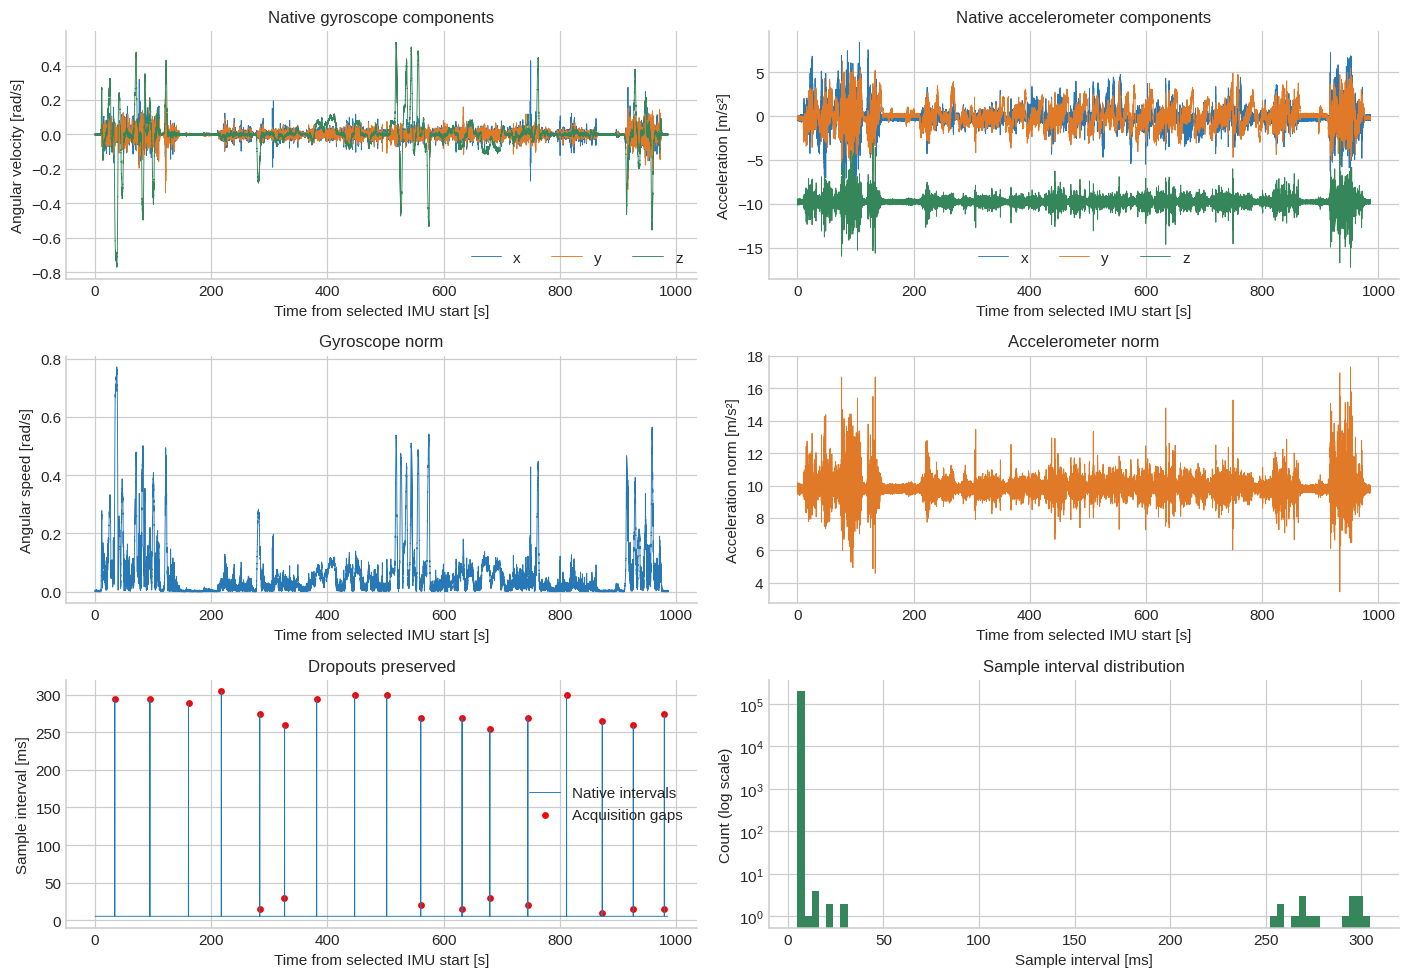

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9))
for axis, color, label in zip(range(3), COLORS, ["x", "y", "z"]):
    axes[0, 0].plot(t_imu, imu.data_gyr[:, axis], color=color, lw=.6, label=label)
    axes[0, 1].plot(t_imu, imu.data_acc[:, axis], color=color, lw=.6, label=label)
axes[0, 0].set(ylabel="Angular velocity [rad/s]", title="Native gyroscope components")
axes[0, 1].set(ylabel="Acceleration [m/s²]", title="Native accelerometer components")
axes[0, 0].legend(ncol=3)
axes[0, 1].legend(ncol=3)
axes[1, 0].plot(t_imu, np.linalg.norm(imu.data_gyr, axis=1), color=COLORS[0], lw=.6)
axes[1, 1].plot(t_imu, np.linalg.norm(imu.data_acc, axis=1), color=COLORS[1], lw=.6)
axes[1, 0].set(ylabel="Angular speed [rad/s]", title="Gyroscope norm")
axes[1, 1].set(ylabel="Acceleration norm [m/s²]", title="Accelerometer norm")
dt = np.diff(imu.timestamps_ns).astype(float) * 1e-9
gaps = stats["gap_indices"]
axes[2, 0].plot(t_imu[1:], dt * 1000, lw=.6, label="Native intervals")
axes[2, 0].scatter(t_imu[gaps + 1], dt[gaps] * 1000, c="red", s=12, label="Acquisition gaps")
axes[2, 0].set(ylabel="Sample interval [ms]", title="Dropouts preserved")
axes[2, 0].legend()
axes[2, 1].hist(dt * 1000, bins=80, color=COLORS[2], log=True)
axes[2, 1].set(xlabel="Sample interval [ms]", ylabel="Count (log scale)", title="Sample interval distribution")
for ax in axes[:, 0]:
    ax.set_xlabel("Time from selected IMU start [s]")
axes[0, 1].set_xlabel("Time from selected IMU start [s]")
axes[1, 1].set_xlabel("Time from selected IMU start [s]")
show_figure(fig)

### Optional comparison sources (disabled by default)

Raw count: 196429 infilled count: 197194


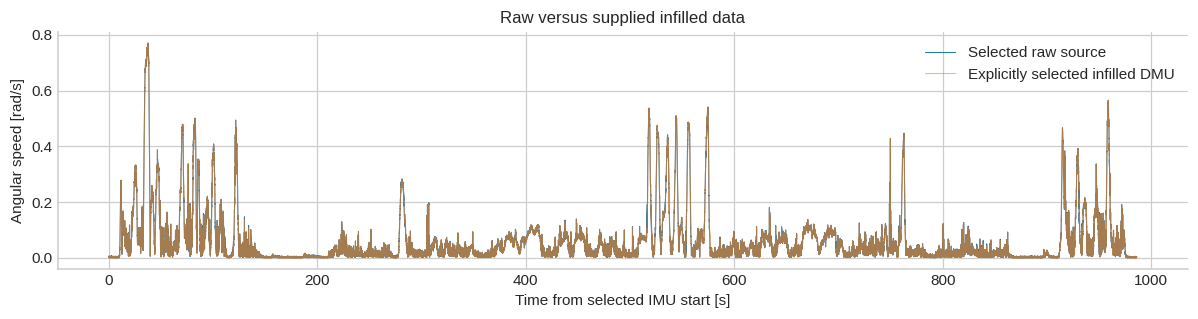

Aeva IMU: (98597, 3) {'count': 98597, 'start_s': 1733248461.889525, 'end_s': 1733249447.857711, 'duration_s': 985.9681860000001, 'median_dt_s': 0.01, 'frequency_hz': 100.0, 'min_dt_s': 0.003026, 'max_dt_s': 0.022027, 'gap_indices': array([29411, 40647]), 'gap_durations_s': array([0.015593, 0.022027])}


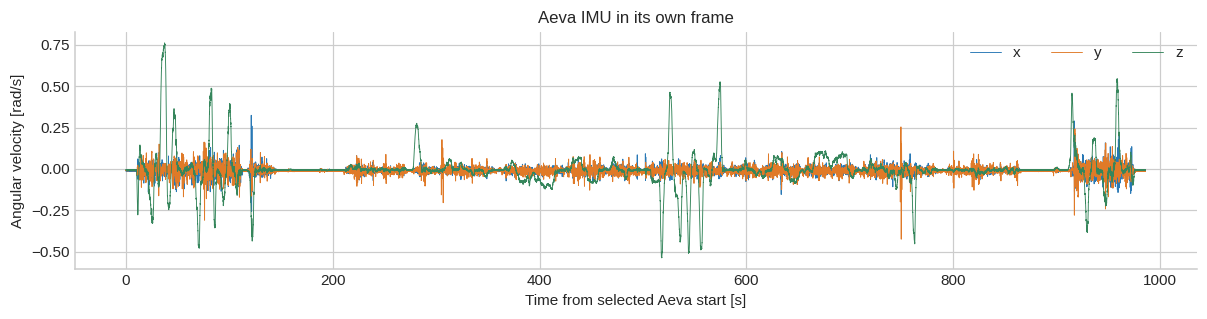

In [5]:
if COMPARE_INFILL and "dmu_infilled" in sequence.sensors["imu"]:
    infilled = sequence.imu("dmu_infilled", time_start=imu.t_utc[0], time_end=imu.t_utc[-1])
    print("Raw count:", len(imu.t_utc), "infilled count:", len(infilled.t_utc))
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(t_imu, np.linalg.norm(imu.data_gyr, axis=1), lw=.7, label="Selected raw source")
    ax.plot(relative_seconds(infilled.timestamps_ns, imu.timestamps_ns[0]), np.linalg.norm(infilled.data_gyr, axis=1),
            lw=.7, alpha=.6, label="Explicitly selected infilled DMU")
    ax.set(xlabel="Time from selected IMU start [s]", ylabel="Angular speed [rad/s]", title="Raw versus supplied infilled data")
    ax.legend()
    show_figure(fig)
if SHOW_AEVA_IMU and "aeva" in sequence.sensors["imu"]:
    aeva = sequence.imu("aeva", time_start=imu.t_utc[0], time_end=imu.t_utc[-1])
    print("Aeva IMU:", aeva.data_gyr.shape, timestamp_statistics(aeva.timestamps_ns))
    fig, ax = plt.subplots(figsize=(11, 3))
    for axis, color, label in zip(range(3), COLORS, ["x", "y", "z"]):
        ax.plot(relative_seconds(aeva.timestamps_ns), aeva.data_gyr[:, axis], color=color, lw=.6, label=label)
    ax.set(xlabel="Time from selected Aeva start [s]", ylabel="Angular velocity [rad/s]", title="Aeva IMU in its own frame")
    ax.legend(ncol=3)
    show_figure(fig)

## B. Ground-truth LiDAR poses
`T_world_lidar` maps sensor points to `ENU_ref`. Angles plotted below are the original CSV roll, pitch and heading in radians, using the official passive rotation convention. Relative transforms map the later frame into the earlier frame. They are derived reference motion, not independent LiDAR odometry.

In [6]:
trajectory = sequence.lidar_poses(source=LIDAR_SOURCE, time_start=TIME_START, time_end=TIME_END)
if len(trajectory.timestamps_ns) < 2:
    raise ValueError("Select an interval containing at least two ground-truth poses")
t_pose = relative_seconds(trajectory.timestamps_ns)
xyz = trajectory.poses_T_W_L[:, :3, 3]
relative = trajectory.relative()
translation_m, rotation_rad = motion_magnitudes(relative.relative_poses_se3)
print("Ground-truth poses:", trajectory.poses_T_W_L.shape)
print(f"Trajectory duration: {t_pose[-1]:.3f} s")
print(f"Total travelled distance: {np.linalg.norm(np.diff(xyz, axis=0), axis=1).sum():.3f} m")
print("Example T_lidar_i_lidar_j (maps j into i):\n", relative.relative_poses_se3[0])
print("Stride-five relative motion:", trajectory.relative(frame_stride=5).relative_poses_se3.shape if len(xyz) > 5 else "Too short")

Ground-truth poses: (9480, 4, 4)
Trajectory duration: 985.744 s
Total travelled distance: 7932.745 m
Example T_lidar_i_lidar_j (maps j into i):
 [[ 9.99999999e-01 -1.60913292e-05  3.00371456e-05  1.82621429e-04]
 [ 1.60913550e-05  1.00000000e+00 -8.57302412e-07 -9.52861424e-05]
 [-3.00371318e-05  8.57785750e-07  1.00000000e+00 -6.33381928e-06]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]
Stride-five relative motion: (1895, 4, 4)


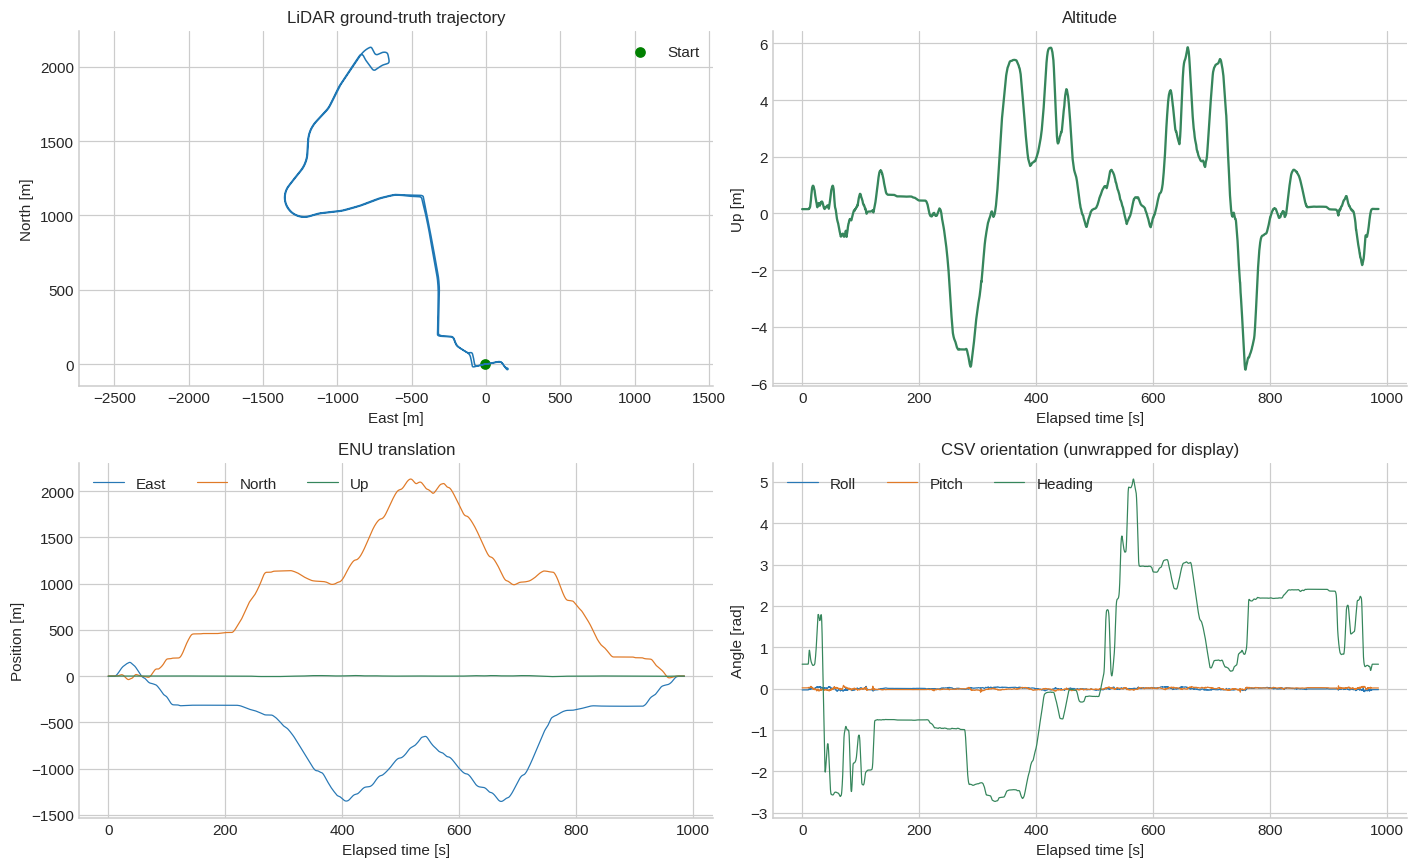

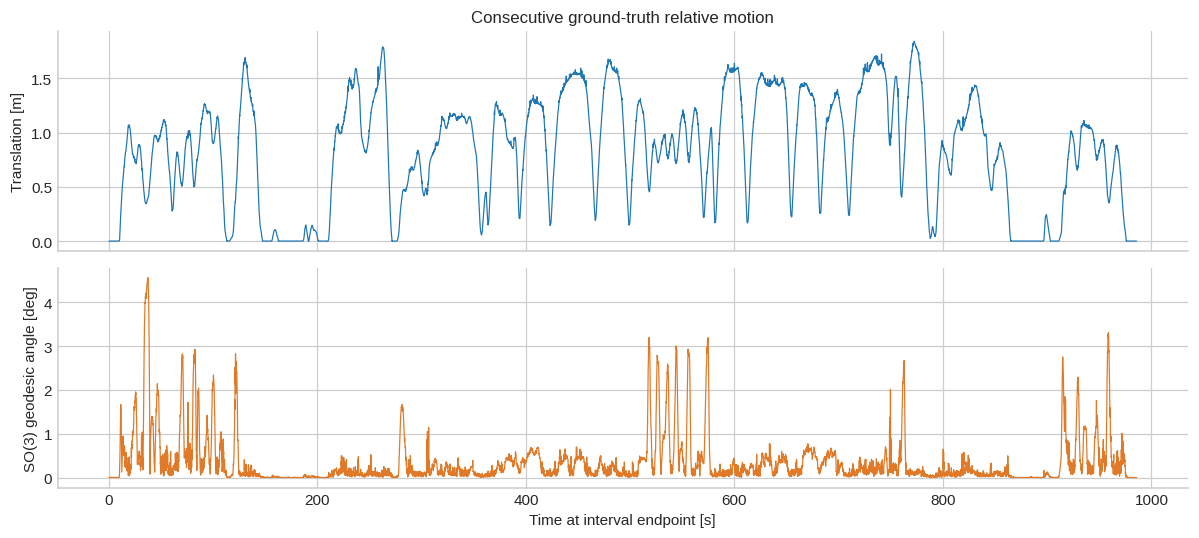

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(xyz[:, 0], xyz[:, 1], lw=1)
axes[0, 0].scatter(*xyz[0, :2], color="green", label="Start")
axes[0, 0].set(xlabel="East [m]", ylabel="North [m]", title="LiDAR ground-truth trajectory")
axes[0, 0].set_aspect("equal", adjustable="datalim")
axes[0, 0].legend()
axes[0, 1].plot(t_pose, xyz[:, 2], color=COLORS[2])
axes[0, 1].set(xlabel="Elapsed time [s]", ylabel="Up [m]", title="Altitude")
for axis, color, label in zip(range(3), COLORS, ["East", "North", "Up"]):
    axes[1, 0].plot(t_pose, xyz[:, axis], color=color, lw=.8, label=label)
for axis, color, label in zip(range(3), COLORS, ["Roll", "Pitch", "Heading"]):
    axes[1, 1].plot(t_pose, np.unwrap(trajectory.rpy_rad[:, axis]), color=color, lw=.8, label=label)
axes[1, 0].set(xlabel="Elapsed time [s]", ylabel="Position [m]", title="ENU translation")
axes[1, 1].set(xlabel="Elapsed time [s]", ylabel="Angle [rad]", title="CSV orientation (unwrapped for display)")
axes[1, 0].legend(ncol=3)
axes[1, 1].legend(ncol=3)
show_figure(fig)
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(t_pose[1:], translation_m, lw=.8)
axes[0].set(ylabel="Translation [m]", title="Consecutive ground-truth relative motion")
axes[1].plot(t_pose[1:], np.rad2deg(rotation_rad), color=COLORS[1], lw=.8)
axes[1].set(xlabel="Time at interval endpoint [s]", ylabel="SO(3) geodesic angle [deg]")
show_figure(fig)

## C. A representative raw point cloud
Velodyne stores `[x,y,z,intensity,laser_id,offset_s]` in its LiDAR frame, with signed seconds relative to scan midpoint. Aeva stores ten float32 words: XYZ, radial velocity, intensity, quality, reflectivity, raw point time and two opaque flag words; its filename denotes scan start. The Aeva time/flag words remain unmodified. Subsampling is deterministic and used only for visualization.

Scan: 1733248954734512.bin UTC timestamp: 1733248954.734512
Total stored points: 210703 visualized points: 10000
XYZ bounds [m]: [-138.94992  -132.2615     -3.226765] [168.26814  164.37907   30.823448]
Intensity min/max: 0.0 255.0
Raw point time min/max (seconds for Velodyne; stored units for Aeva): -0.051742077 0.05174303
Ground-truth scan pose:
 [[ 9.83831949e-01 -1.78218280e-01  1.76901328e-02 -9.08041479e+02]
 [ 1.78584108e-01  9.83681837e-01 -2.18577208e-02  1.98329197e+03]
 [-1.35060169e-02  2.46635006e-02  9.99604571e-01 -2.63429835e-02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


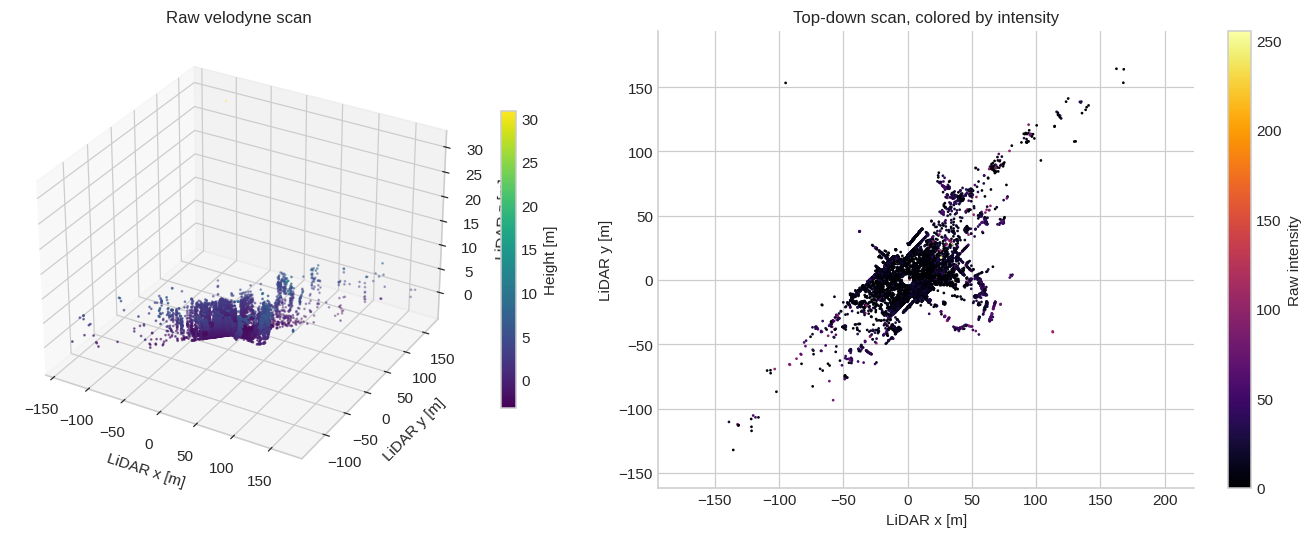

In [8]:
scans = sequence.lidar_scans(source=LIDAR_SOURCE, time_start=TIME_START, time_end=TIME_END)
if not scans:
    raise FileNotFoundError("No Velodyne scans are available in the selected interval")
scan_index = len(scans) // 2
scan = scans[scan_index]
points = scan.load(max_points=POINTS_PER_SCAN)
print("Scan:", scan.path.name, "UTC timestamp:", scan.timestamp_s)
print("Total stored points:", scan.path.stat().st_size // (4 * LIDAR_SOURCES[LIDAR_SOURCE][1]), "visualized points:", len(points))
print("XYZ bounds [m]:", points[:, :3].min(axis=0), points[:, :3].max(axis=0))
intensity_column = 3 if LIDAR_SOURCE == "velodyne" else 4
print("Intensity min/max:", points[:, intensity_column].min(), points[:, intensity_column].max())
time_column = 5 if LIDAR_SOURCE == "velodyne" else 7
print("Raw point time min/max (seconds for Velodyne; stored units for Aeva):", points[:, time_column].min(), points[:, time_column].max())
print("Ground-truth scan pose:\n", trajectory.match([scan.timestamp_ns])[0])
fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(121, projection="3d")
cloud = ax.scatter(*points[:, :3].T, c=points[:, 2], s=.6, cmap="viridis")
ax.set(xlabel="LiDAR x [m]", ylabel="LiDAR y [m]", zlabel="LiDAR z [m]", title=f"Raw {LIDAR_SOURCE} scan")
fig.colorbar(cloud, ax=ax, label="Height [m]", shrink=.65)
ax2 = fig.add_subplot(122)
cloud2 = ax2.scatter(points[:, 0], points[:, 1], c=points[:, intensity_column], s=.6, cmap="inferno")
ax2.set(xlabel="LiDAR x [m]", ylabel="LiDAR y [m]", title="Top-down scan, colored by intensity")
ax2.set_aspect("equal", adjustable="datalim")
fig.colorbar(cloud2, ax=ax2, label="Raw intensity")
show_figure(fig)

## D. Ground-truth-aligned accumulated LiDAR scans
Use at most `MAX_LIDAR_SCANS` adjacent scans near the representative scan. The first selected LiDAR frame is the local reference. This is a direct accumulation, with no deskew, scan matching, optimization or rejection of moving objects; it is not a SLAM map.

Accumulated scans: 20 points: 200000


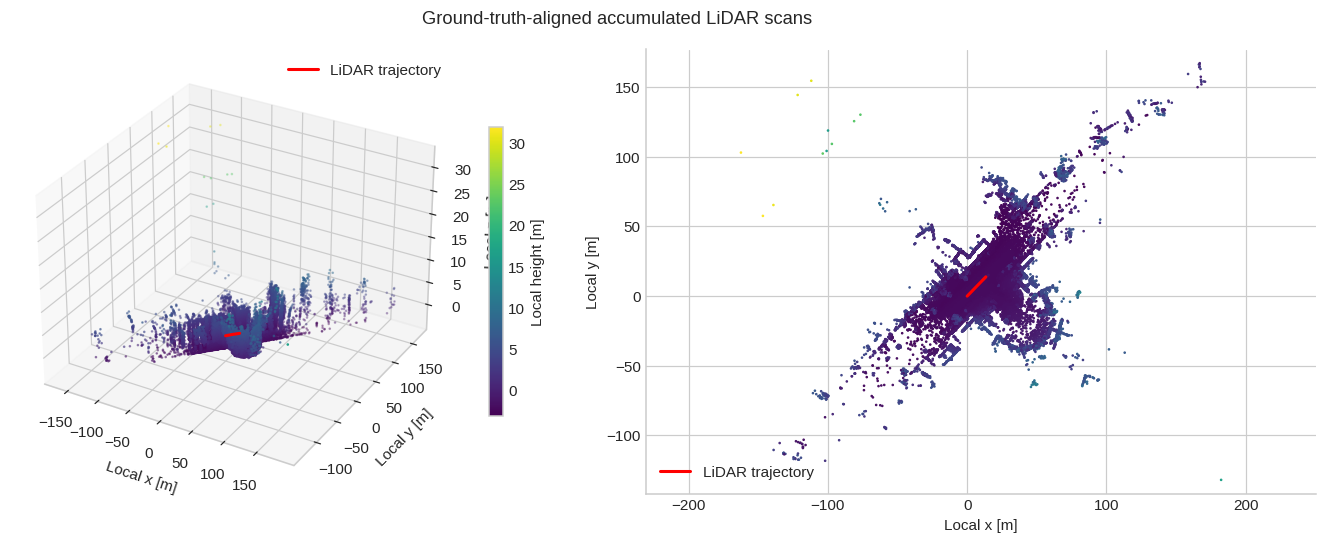

In [9]:
if MAX_LIDAR_SCANS < 1:
    raise ValueError("MAX_LIDAR_SCANS must be positive")
selected_scans = scans[scan_index:scan_index + MAX_LIDAR_SCANS]
cloud_xyz, local_poses = accumulate_lidar_scans(selected_scans, trajectory, points_per_scan=POINTS_PER_SCAN)
local_xyz = local_poses[:, :3, 3]
print("Accumulated scans:", len(selected_scans), "points:", len(cloud_xyz))
# Limit Matplotlib rendering too; the returned accumulation remains available.
plot_xyz = cloud_xyz[::max(1, int(np.ceil(len(cloud_xyz) / 50_000))) ]
fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(121, projection="3d")
cloud_plot = ax.scatter(*plot_xyz.T, c=plot_xyz[:, 2], s=.5, cmap="viridis")
ax.plot(*local_xyz.T, c="red", lw=2, label="LiDAR trajectory")
ax.set(xlabel="Local x [m]", ylabel="Local y [m]", zlabel="Local z [m]")
ax.legend()
fig.colorbar(cloud_plot, ax=ax, label="Local height [m]", shrink=.65)
ax2 = fig.add_subplot(122)
ax2.scatter(plot_xyz[:, 0], plot_xyz[:, 1], c=plot_xyz[:, 2], s=.5, cmap="viridis")
ax2.plot(local_xyz[:, 0], local_xyz[:, 1], c="red", lw=2, label="LiDAR trajectory")
ax2.set(xlabel="Local x [m]", ylabel="Local y [m]")
ax2.set_aspect("equal", adjustable="datalim")
ax2.legend()
fig.suptitle("Ground-truth-aligned accumulated LiDAR scans")
show_figure(fig)

## E. IMU/LiDAR synchronization
Select a short common interval without resampling signals. Match scan timestamps to nearest IMU samples using integer nanoseconds and an explicit tolerance. Pose lookup remains exact by default; `PoseTrajectory.match()` also supports opt-in SLERP/translation interpolation with a required maximum bracket gap and no extrapolation.

Raw DMU dropouts can leave LiDAR scans without a close IMU measurement. Rejected matches are explicitly marked with index -1 and drawn in red; they are never silently accepted or filled.

Synchronized UTC window [s]: 1733248954.858566 1733248964.858566
IMU / GT pose / scan counts: 1943 96 96
Accepted matches: 95 rejected across acquisition gaps: 1
Maximum absolute scan-to-IMU timestamp mismatch [ms]: 126.32884800000002


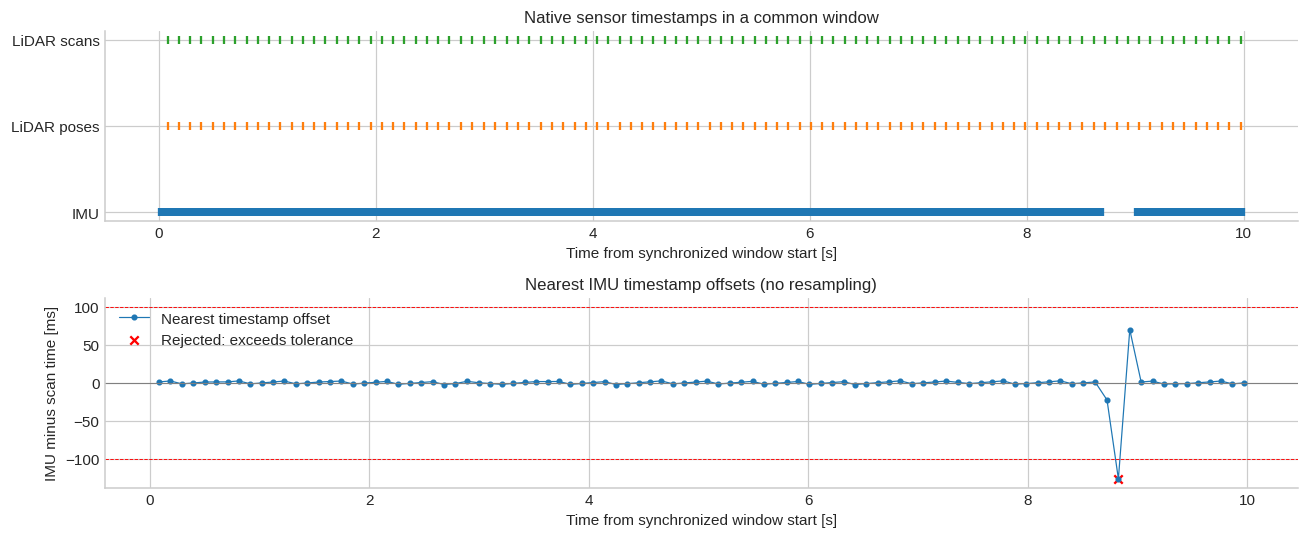

In [10]:
common_start_ns = max(imu.timestamps_ns[0], trajectory.timestamps_ns[0], scans[0].timestamp_ns)
common_end_ns = min(imu.timestamps_ns[-1], trajectory.timestamps_ns[-1], scans[-1].timestamp_ns)
if common_end_ns <= common_start_ns:
    raise ValueError("The selected IMU and LiDAR sources have no common coverage")
window_start_ns = (common_start_ns + common_end_ns) // 2
window_end_ns = min(window_start_ns + int(SYNC_WINDOW_S * 1e9), common_end_ns)
# Decimal strings avoid rounding interval endpoints through float64 epochs.
from decimal import Decimal
window_start = str(Decimal(int(window_start_ns)) / Decimal(1_000_000_000))
window_end = str(Decimal(int(window_end_ns)) / Decimal(1_000_000_000))
imu_window = imu.select(window_start, window_end)
pose_window = trajectory.select(window_start, window_end)
scan_window = sequence.lidar_scans(source=LIDAR_SOURCE, time_start=window_start, time_end=window_end)
scan_ns = np.array([s.timestamp_ns for s in scan_window], dtype=np.int64)
indices, match_delta_s = nearest_timestamps(imu_window.timestamps_ns, scan_ns, tolerance_s=SYNC_TOLERANCE_S, allow_unmatched=True)
accepted = indices >= 0
matched_poses = trajectory.match(scan_ns)
print("Synchronized UTC window [s]:", window_start, window_end)
print("IMU / GT pose / scan counts:", len(imu_window.t_utc), len(pose_window.timestamps_ns), len(scan_window))
print("Accepted matches:", int(accepted.sum()), "rejected across acquisition gaps:", int((~accepted).sum()))
print("Maximum absolute scan-to-IMU timestamp mismatch [ms]:", np.max(np.abs(match_delta_s), initial=0) * 1000)
fig, axes = plt.subplots(2, 1, figsize=(12, 5))
for row, (name, times) in enumerate([("IMU", imu_window.timestamps_ns), ("LiDAR poses", pose_window.timestamps_ns), ("LiDAR scans", scan_ns)]):
    axes[0].scatter(relative_seconds(times, window_start_ns), np.full(len(times), row), marker="|", s=25, label=name)
axes[0].set(yticks=[0, 1, 2], yticklabels=["IMU", "LiDAR poses", "LiDAR scans"],
            xlabel="Time from synchronized window start [s]", title="Native sensor timestamps in a common window")
axes[1].plot(relative_seconds(scan_ns, window_start_ns), match_delta_s * 1000, ".-", lw=.8, label="Nearest timestamp offset")
axes[1].scatter(relative_seconds(scan_ns[~accepted], window_start_ns), match_delta_s[~accepted] * 1000,
                color="red", marker="x", s=30, label="Rejected: exceeds tolerance")
axes[1].axhline(SYNC_TOLERANCE_S * 1000, color="red", ls="--", lw=.6)
axes[1].axhline(-SYNC_TOLERANCE_S * 1000, color="red", ls="--", lw=.6)
axes[1].legend()
axes[1].axhline(0, color="gray", lw=.7)
axes[1].set(xlabel="Time from synchronized window start [s]", ylabel="IMU minus scan time [ms]",
            title="Nearest IMU timestamp offsets (no resampling)")
show_figure(fig)

## F. Compare all LiDAR sources: Velodyne and Aeva
Aeva includes **both a FMCW LiDAR and a separate IMU stream**. This section compares all available LiDARs. Complete scan counts, byte sizes and point counts are exact inventory statistics; geometry statistics use a small deterministic sample, rather than loading whole sequences. Observed angular coverage is a sample statistic, not a hardware field-of-view specification.

Velodyne timestamps denote scan midpoints; Aeva timestamps denote scan starts. Individual scans also contain motion distortion. Comparisons below retain those time conventions, use each source's own pose file and do not silently deskew scans.

In [11]:
import pandas as pd
from IPython.display import display
from boreas_dataset.sensor_statistics import lidar_statistics
from boreas_dataset.lidar import LIDAR_SOURCES
LIDAR_COMPARISON_SOURCES = ("velodyne", "aeva")
LIDAR_STATS_SAMPLE_SCANS = 5
LIDAR_STATS_POINTS_PER_SCAN = 20_000
available_lidars = [source for source in LIDAR_COMPARISON_SOURCES if source in sequence.sensors["lidar"]]
lidar_table = pd.DataFrame([lidar_statistics(sequence.root, source=source,
                            sample_scans=LIDAR_STATS_SAMPLE_SCANS, max_points_per_scan=LIDAR_STATS_POINTS_PER_SCAN)
                            for source in available_lidars]).set_index("source")
display(lidar_table[["scans", "duration_s", "median_rate_hz", "gaps", "max_dt_ms", "scan_time_reference",
                     "points_per_scan_min", "points_per_scan_p50", "points_per_scan_max", "total_bytes"]])
display(lidar_table[["sampled_scans", "sampled_points", "range_p50_m", "range_p95_m",
                     "observed_azimuth_span_deg", "point_time_unit", "doppler_available"]])
print("Missing optional LiDARs:", [source for source in LIDAR_COMPARISON_SOURCES if source not in available_lidars] or "none")
print("Aeva point-time and flag words are preserved raw. The downloaded time field has an apparent nanosecond scale, not seconds; no unverified conversion is applied.")

,scans,duration_s,median_rate_hz,gaps,max_dt_ms,scan_time_reference,points_per_scan_min,points_per_scan_p50,points_per_scan_max,total_bytes
source,,,,,,,,,,
velodyne,9480,985.743744,9.640506,0,114.014,midpoint,177416,209994.0,230502,47205872664
aeva,9860,985.899990,9.999900,0,120.589,start,45194,96717.0,126323,37376613880


,sampled_scans,sampled_points,range_p50_m,range_p95_m,observed_azimuth_span_deg,point_time_unit,doppler_available
source,,,,,,,
velodyne,5,100000,18.524002,80.132404,359.909978,s,False
aeva,5,100000,23.772123,83.787943,119.083464,"raw; apparent ns scale, unverified",True


Missing optional LiDARs: none
Aeva point-time and flag words are preserved raw. The downloaded time field has an apparent nanosecond scale, not seconds; no unverified conversion is applied.


velodyne file 1733248954838257.bin scan-minus-query [ms] -20.309 timestamp reference midpoint
aeva file 1733248954899576.bin scan-minus-query [ms] 41.010000000000005 timestamp reference start


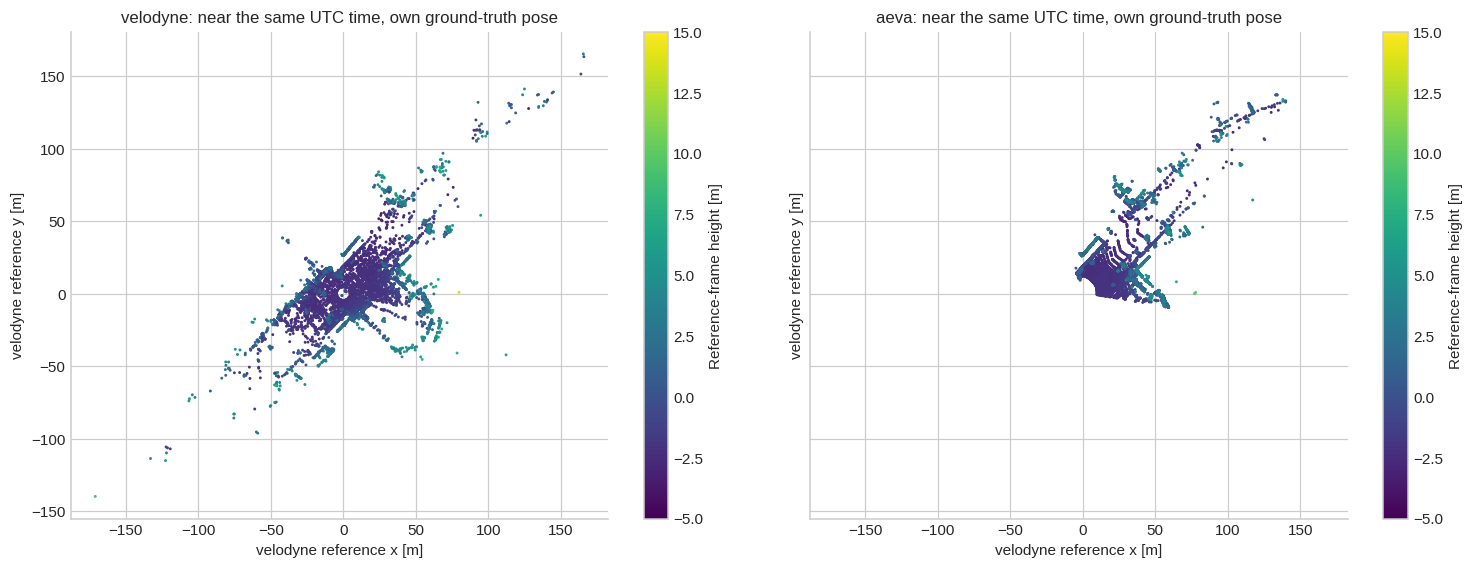

In [12]:
comparison_scans = {source: sequence.lidar_scans(source=source, time_start=TIME_START, time_end=TIME_END)
                    for source in available_lidars}
comparison_poses = {source: sequence.lidar_poses(source=source, time_start=TIME_START, time_end=TIME_END)
                    for source in available_lidars}
nonempty_sources = [source for source in available_lidars if comparison_scans[source] and len(comparison_poses[source].timestamps_ns)]
shared_start_ns = max(comparison_scans[source][0].timestamp_ns for source in nonempty_sources)
shared_end_ns = min(comparison_scans[source][-1].timestamp_ns for source in nonempty_sources)
if shared_start_ns > shared_end_ns:
    raise ValueError("The selected LiDAR sources have no common coverage")
query_ns = (shared_start_ns + shared_end_ns) // 2
chosen_scans = {}
chosen_poses = {}
for source in nonempty_sources:
    source_scans = comparison_scans[source]
    idx, offset = nearest_timestamps([s.timestamp_ns for s in source_scans], [query_ns], tolerance_s=.2)
    chosen_scans[source] = source_scans[int(idx[0])]
    chosen_poses[source] = comparison_poses[source].match([chosen_scans[source].timestamp_ns])[0]
    print(source, "file", chosen_scans[source].path.name, "scan-minus-query [ms]", offset[0] * 1000,
          "timestamp reference", chosen_scans[source].timestamp_reference)
anchor_source = nonempty_sources[0]
anchor_pose = chosen_poses[anchor_source]
fig, axes = plt.subplots(1, len(nonempty_sources), figsize=(7 * len(nonempty_sources), 5), squeeze=False, sharex=True, sharey=True)
for ax, source in zip(axes[0], nonempty_sources):
    raw = chosen_scans[source].load(max_points=POINTS_PER_SCAN)
    T_anchor_sensor = np.linalg.solve(anchor_pose, chosen_poses[source])
    points_anchor = raw[:, :3] @ T_anchor_sensor[:3, :3].T + T_anchor_sensor[:3, 3]
    cloud_plot = ax.scatter(points_anchor[:, 0], points_anchor[:, 1], c=points_anchor[:, 2], s=.8, cmap="viridis", vmin=-5, vmax=15)
    ax.set(xlabel=f"{anchor_source} reference x [m]", ylabel=f"{anchor_source} reference y [m]",
           title=f"{source}: near the same UTC time, own ground-truth pose")
    ax.set_aspect("equal", adjustable="box")
    fig.colorbar(cloud_plot, ax=ax, label="Reference-frame height [m]")
show_figure(fig)

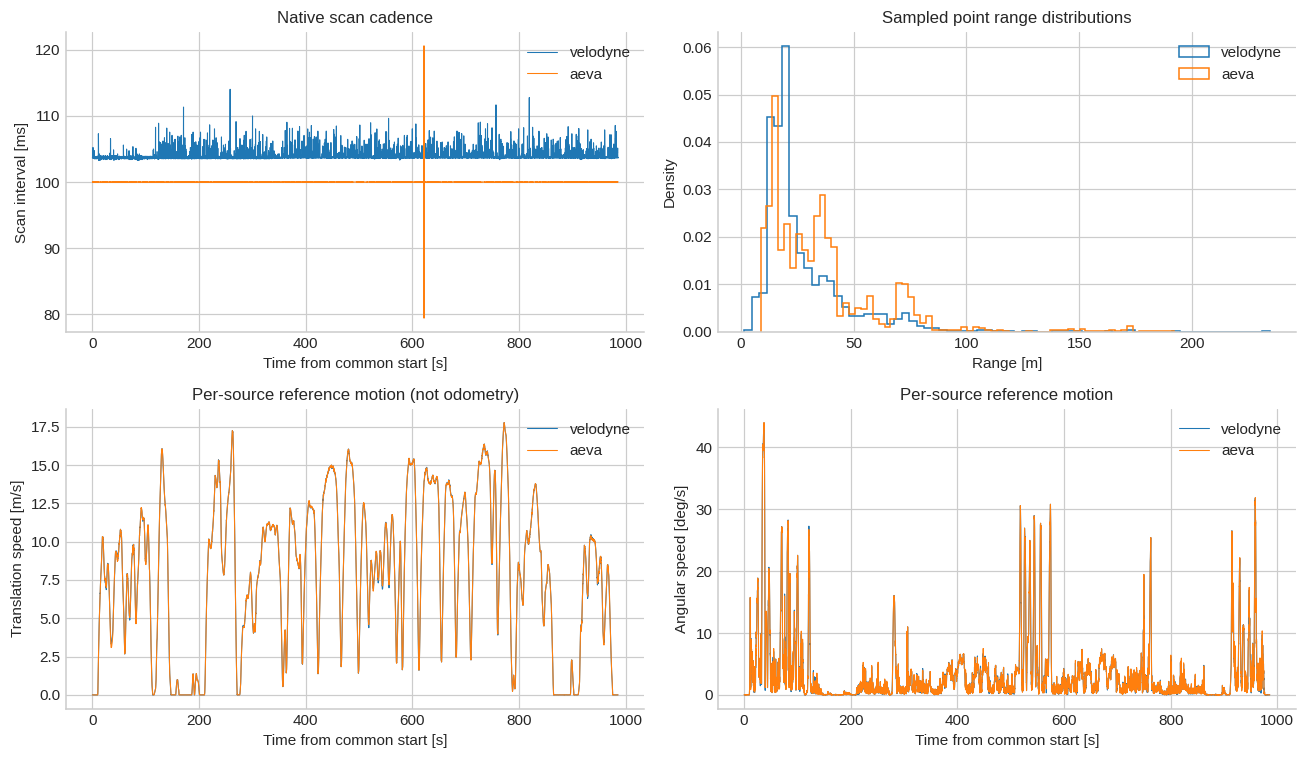

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for source in nonempty_sources:
    source_scans = comparison_scans[source]
    source_ns = np.array([s.timestamp_ns for s in source_scans], dtype=np.int64)
    time = relative_seconds(source_ns, shared_start_ns)
    axes[0, 0].plot(time[1:], np.diff(source_ns) * 1e-6, lw=.7, label=source)
    raw = chosen_scans[source].load(max_points=LIDAR_STATS_POINTS_PER_SCAN)
    axes[0, 1].hist(np.linalg.norm(raw[:, :3], axis=1), bins=70, histtype="step", density=True, label=source)
    poses = comparison_poses[source]
    if len(poses.timestamps_ns) > 1:
        motion = poses.relative()
        distance, angle = motion_magnitudes(motion.relative_poses_se3)
        period = np.diff(poses.timestamps_ns) * 1e-9
        axes[1, 0].plot(relative_seconds(poses.timestamps_ns, shared_start_ns)[1:], distance / period, lw=.7, label=source)
        axes[1, 1].plot(relative_seconds(poses.timestamps_ns, shared_start_ns)[1:], np.rad2deg(angle) / period, lw=.7, label=source)
axes[0, 0].set(xlabel="Time from common start [s]", ylabel="Scan interval [ms]", title="Native scan cadence")
axes[0, 1].set(xlabel="Range [m]", ylabel="Density", title="Sampled point range distributions")
axes[1, 0].set(xlabel="Time from common start [s]", ylabel="Translation speed [m/s]", title="Per-source reference motion (not odometry)")
axes[1, 1].set(xlabel="Time from common start [s]", ylabel="Angular speed [deg/s]", title="Per-source reference motion")
for ax in axes.flat:
    ax.legend()
show_figure(fig)

### Independent odometry caches, when extracted
The importer below registers scans without reading the IMU or reference poses and writes CSVs directly in the sequence folder. These caches are independent scan estimates; the preceding pose plots remain ground truth. Aeva Doppler values are preserved in raw data but the adapted ICP uses XYZ only. Fitness/RMSE describe registration fit, not guaranteed pose accuracy.

In [14]:
from boreas_dataset.odometry import load_lidar_data_csv
odometry_rows = []
for source in available_lidars:
    cache_path = sequence.root / f"lidar_odometry_{source}.csv"
    if not cache_path.is_file():
        print("Not extracted yet:", cache_path.name)
        continue
    odom = load_lidar_data_csv(cache_path)
    shift, angle = motion_magnitudes(odom.relative_poses_se3)
    odometry_rows.append({"source": source, "intervals": len(odom.timestamps_s),
                         "median_fitness": np.median(odom.fitness), "fitness_p05": np.percentile(odom.fitness, 5),
                         "median_rmse_m": np.median(odom.inlier_rmse), "rmse_p95_m": np.percentile(odom.inlier_rmse, 95),
                         "median_translation_m": np.median(shift), "median_rotation_deg": np.rad2deg(np.median(angle)),
                         "independent": odom.metadata.get("independent_odometry"), "deskewed": odom.metadata.get("deskewed"),
                         "max_scans_limit": odom.metadata.get("max_scans"), "scan_step": odom.metadata.get("scan_step")})
if odometry_rows:
    display(pd.DataFrame(odometry_rows).set_index("source"))

,intervals,median_fitness,fitness_p05,median_rmse_m,rmse_p95_m,median_translation_m,median_rotation_deg,independent,deskewed,max_scans_limit,scan_step
source,,,,,,,,,,,
velodyne,9479,0.984537,0.967122,0.163558,0.191163,0.862677,0.134523,True,False,None,1
aeva,9859,0.980036,0.952765,0.187018,0.225144,0.863228,0.130017,True,False,None,1


**What to use next**

- **Velodyne LiDAR:** broad surrounding geometry and many points per scan; a natural primary XYZ registration input.
- **Aeva LiDAR:** a second independent LiDAR with a narrower forward view and Doppler measurements. Its measured coverage/range and registration diagnostics can justify adding it as another calibration sensor. XYZ ICP does not exploit Doppler.
- Keep each LiDAR's timestamp reference, coordinate frame and extrinsic distinct. Raw-point time/flag interpretation for Aeva needs verification before implementing deskew or flag-based rejection; the current XYZ importer does neither.
- Reference trajectories can evaluate registration, but they must not be used to initialize an odometry stream claimed to be independent.

From the repository root, one command processes all downloaded sequences and both available LiDARs, skipping missing sensors and existing outputs:

```bash
python src/boreas_dataset/import_lidar_odometry.py /mnt/d/Downloads/MobRobLab/BoreasDataset
```

Outputs are `<sequence>/lidar_odometry_velodyne.csv` and `<sequence>/lidar_odometry_aeva.csv`. Use `--dry-run` to list jobs and `--overwrite` to replace an existing cache. CPU/CUDA, local-map, multiscale, robust-kernel and worker options follow the supplied KAIST importer. No extra output directories are created.

For later calibration, use the actual `T_applanix_dmu` and `T_applanix_lidar` matrices to keep the sensor frames distinct. Do not treat the Applanix-derived relative poses as an independently measured LiDAR benchmark. Acquiring independent motion observations and adding a dedicated `obscalib` window adapter are separate next steps.